### Importing Necessary Libraries & Connecting to Drive

In [1]:
# # # %%capture
# # # !pip install spektral (already installed) (already installed) (already installed)

import os
import numpy as np
import pandas as pd
import glob
from tqdm import tqdm
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization, Conv1D, MaxPooling1D, Flatten, Activation, GlobalAveragePooling1D, Lambda, TimeDistributed, Reshape, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.models import Model, load_model

from spektral.layers import GCNConv

from collections import Counter

RANDOM_SEED = 42

In [2]:
import os
import sys

# Dual-environment path auto-configuration (Google Colab vs Local Windows/Linux IDE)
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    target_dir = '/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Detection'
    if os.path.exists(target_dir):
        os.chdir(target_dir)
else:
    local_candidates = [
        os.path.abspath(r'e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Detection'),
        os.path.abspath('./Alpha Band Analysis/Alpha Band Detection'),
        os.path.abspath('.')
    ]
    for p in local_candidates:
        if os.path.exists(p) and 'Alpha Band Detection' in p:
            os.chdir(p)
            break

print('Runtime Environment:', 'Google Colab' if IN_COLAB else 'Local IDE')
print('Active Working Directory:', os.getcwd())


Runtime Environment: Local IDE
Active Working Directory: e:\Obaidul Haque\Alpha Band Analysis\Alpha Band Detection


### Loading Preprocessed Data, Window Creation

In [3]:
def get_max_occurring_from_last_n(arr, n=5):
    """
    Finds the maximum occurring item from the last 'n' elements of an array.

    Args:
        arr (list): The input array.
        n (int): The number of last items to consider. Defaults to 5.

    Returns:
        tuple: A tuple containing the maximum occurring item and its count.
               Returns (None, 0) if the array is empty or 'n' is non-positive.
    """
    if not arr or n <= 0:
        return None, 0

    last_n_items = arr[-n:]

    if not last_n_items:
        return None, 0

    flattened_items = [item[0] for item in last_n_items if isinstance(item, list) and len(item) > 0]

    if not flattened_items:
        return None, 0

    item_counts = Counter(flattened_items)
    most_common_item = item_counts.most_common(1)

    if most_common_item:
        return most_common_item[0]
    else:
        return None, 0

def get_file_paths(folder_path):
  pattern = os.path.join(folder_path, '*')
  file_paths = glob.glob(pattern)

  file_paths = [path for path in file_paths if os.path.isfile(path)]
  return file_paths

def create_sliding_window(normalized_combined_features_2d, labels, window_size, stride=1):
  # --- Sequence Length Considerations (Sliding Windows) ---
  print("\n--- Sliding Windows ---")

  if normalized_combined_features_2d.shape[0] > 0:
      num_segments = normalized_combined_features_2d.shape[0]

      sliding_windows_data = []
      sliding_windows_labels = []

      for i in range(0, num_segments - window_size + 1, stride):
          window_data = normalized_combined_features_2d[i:i + window_size]
          window_labels = labels[i:i + window_size]

          sliding_windows_data.append(window_data)
          sliding_windows_labels.append(window_labels)

      print(f"Number of total segments: {num_segments}")
      print(f"Sliding window size: {window_size} segments")
      print(f"Stride: {stride} segments")
      print(f"Number of sliding windows created: {len(sliding_windows_data)}")

      if sliding_windows_data and sliding_windows_labels:
          print(f"Shape of the first sliding window data: {sliding_windows_data[0].shape}")
          print(f"Shape of the first sliding window labels: {np.array(sliding_windows_labels[0]).shape}")

          # --- Presence Labeling for Sliding Windows ---
          window_presence_labels = []
          for window_label_sequence in sliding_windows_labels:
              max_item_1, _count_1 = get_max_occurring_from_last_n([[int(window_label_sequence[i][0])] for i in range(len(window_label_sequence))])
              window_presence_labels.append(np.array(max_item_1))

          print(f"\nLabels for sliding windows (based on presence): {len(window_presence_labels)}")
          print(f"Example of the first few window labels: {window_presence_labels[:5]}")

          return sliding_windows_data, window_presence_labels
      else:
          print("No sliding windows were created.")
          return None

  else:
      print("No shaped data available to create sliding windows.")

In [4]:
# Dual-environment path resolver (Google Colab Drive vs. Local IDE)
candidate_test_dirs = [
    os.path.abspath("./Preprocessed Data/testing"),
    os.path.abspath(r"e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Detection/Preprocessed Data/testing"),
    "/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Detection/Preprocessed Data/testing"
]
drive_test_dir = next((p for p in candidate_test_dirs if os.path.exists(p) and len(os.listdir(p)) > 0), candidate_test_dirs[0])
local_test_dir = os.path.abspath(r"e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Detection/Preprocessed Data/testing")
fallback_test_dir = os.path.abspath("./Preprocessed Data/testing")

if os.path.exists(drive_test_dir) and len(os.listdir(drive_test_dir)) > 0:
    test_dir = drive_test_dir
elif os.path.exists(local_test_dir) and len(os.listdir(local_test_dir)) > 0:
    test_dir = local_test_dir
elif os.path.exists(fallback_test_dir) and len(os.listdir(fallback_test_dir)) > 0:
    test_dir = fallback_test_dir
else:
    test_dir = drive_test_dir

dataset_test = get_file_paths(test_dir)
print(f"\nNumber of testing samples: {len(dataset_test)}")

X = []
y = []

for file_path in tqdm(dataset_test):
    df = pd.read_csv(file_path)
    data = np.array(df)
    segmented_features_2d = data[:, :-1]
    labels = data[:, -1:].astype('int')

    windows, window_labels = create_sliding_window(normalized_combined_features_2d=segmented_features_2d, labels=labels, window_size=10, stride=1)

    X.append(windows)
    y.append(window_labels)

X = np.vstack(X).astype(np.float32)
y = np.concatenate(y).astype(np.int32)

# Split the shuffled indices
X_test, y_test = X, y

print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")



Number of testing samples: 21


  0%|          | 0/21 [00:00<?, ?it/s]


--- Sliding Windows ---
Number of total segments: 38
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 29
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 29
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]

--- Sliding Windows ---
Number of total segments: 34
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 25
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 25
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]

--- Sliding Windows ---
Number of total segments: 35
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 26
Shape of the first sliding window data: (10, 506)
Shape of the first sliding windo

 19%|█▉        | 4/21 [00:00<00:00, 29.61it/s]


--- Sliding Windows ---
Number of total segments: 31
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 22
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 22
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]

--- Sliding Windows ---
Number of total segments: 41
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 32
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 32
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]

--- Sliding Windows ---
Number of total segments: 45
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 36
Shape of the first sliding window data: (10, 506)
Shape of the first sliding windo


--- Sliding Windows ---
Number of total segments: 49
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 40
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 40
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]


... (5 outputs left out)

 81%|████████  | 17/21 [00:00<00:00, 38.45it/s]


--- Sliding Windows ---
Number of total segments: 23
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 14
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 14
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]

--- Sliding Windows ---
Number of total segments: 33
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 24
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 24
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]

--- Sliding Windows ---
Number of total segments: 23
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 14
Shape of the first sliding window data: (10, 506)
Shape of the first sliding windo

100%|██████████| 21/21 [00:00<00:00, 38.21it/s]


--- Sliding Windows ---
Number of total segments: 25
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 16
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10, 1)

Labels for sliding windows (based on presence): 16
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]
X_test shape: (557, 10, 506)
y_test shape: (557,)


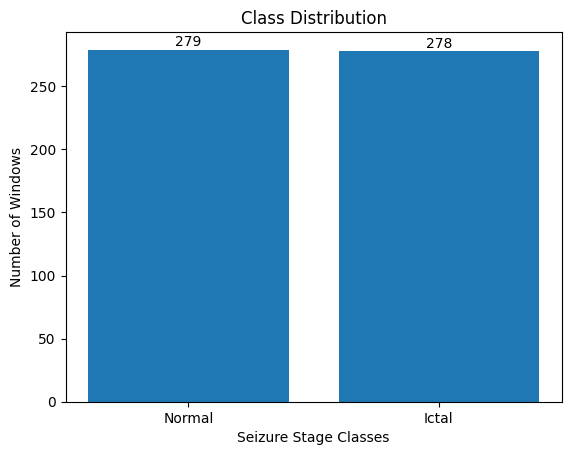

In [5]:
# PLOTTING
y_test_labels = y_test.flatten()
label_count = {}
for label in y_test_labels:
    if label in label_count:
        label_count[label] += 1
    else:
        label_count[label] = 1

categories = ['Normal', 'Ictal']
values = [label_count[0], label_count[1]]

bars = plt.bar(categories, values)

plt.xlabel("Seizure Stage Classes")
plt.ylabel("Number of Windows")
plt.title("Class Distribution")

# Function to add value labels above the bars
def add_value_labels(ax, bars):
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2., height + 0.5,
                f'{height}',
                ha='center', va='bottom')

# Add value labels to the current axes
add_value_labels(plt.gca(), bars)

plt.show()

### Defining Model Architectures

### Testing

In [6]:
# 'X' is data with shape (num_windows, 10, total_features)
num_channels = 23
total_features = X.shape[2]
features_per_channel = total_features // num_channels
if total_features % num_channels != 0:
    raise ValueError("Total features cannot be evenly divided by the number of channels.")

print(f"Calculated Features per channel (F): {features_per_channel}")

# Reshape X to (num_windows, 10, 23, F)
# The new shape separates the channels (nodes) and their features
X_reshaped = X.reshape(X.shape[0], X.shape[1], num_channels, features_per_channel)

print(f"Original X shape: {X.shape}")
print(f"Reshaped X for GCN: {X_reshaped.shape}")

# Now, split the reshaped data
X_test, y_test = X_reshaped, y

print(f"\nX_test shape for GCN: {X_test.shape}")
print(f"X_val shape for GCN: {y_test.shape}")

Calculated Features per channel (F): 22
Original X shape: (557, 10, 506)
Reshaped X for GCN: (557, 10, 23, 22)

X_test shape for GCN: (557, 10, 23, 22)
X_val shape for GCN: (557,)


In [7]:
import numpy as np
import spektral
from scipy.sparse import coo_matrix

# channel and edge definitions
channels = [
    'FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1',
    'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2',
    'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1'
]
channel_indices = {channel: idx for idx, channel in enumerate(channels)}
edges = [
    ('FP1-F7', 'F7-T7'), ('F7-T7', 'T7-P7'), ('T7-P7', 'P7-O1'), ('FP1-F7', 'FP1-F3'),
    ('FP1-F3', 'F3-C3'), ('F3-C3', 'C3-P3'), ('C3-P3', 'P3-O1'), ('P7-O1', 'P3-O1'),
    ('FP2-F4', 'F4-C4'), ('F4-C4', 'C4-P4'), ('C4-P4', 'P4-O2'), ('FP2-F4', 'FP2-F8'),
    ('FP2-F8', 'F8-T8'), ('F8-T8', 'T8-P8-0'), ('T8-P8-0', 'P8-O2'), ('FZ-CZ', 'CZ-PZ'),
    ('P7-T7', 'T7-FT9'), ('T7-FT9', 'FT9-FT10'), ('FT9-FT10', 'FT10-T8'), ('FT10-T8', 'T8-P8-1')
]

# Create an empty adjacency matrix
num_channels = len(channels)
adj_matrix = np.zeros((num_channels, num_channels))

# Populate the adjacency matrix from the edge list
for start, end in edges:
    i, j = channel_indices[start], channel_indices[end]
    adj_matrix[i, j] = 1
    adj_matrix[j, i] = 1 # For an undirected graph

print("Adjacency Matrix shape:", adj_matrix.shape)

# Preprocess the adjacency matrix for GCN
# This adds self-loops and performs symmetric normalization
adj_matrix_normalized = spektral.layers.GCNConv.preprocess(adj_matrix).astype('f4')

# For training, Spektral works well with sparse matrices
adj_matrix_sparse = coo_matrix(adj_matrix_normalized).toarray()

Adjacency Matrix shape: (23, 23)


#### Model Definitions

In [8]:
from tensorflow.keras.layers import LSTM, BatchNormalization

class GCNConvWithNoMask(GCNConv):
    """
    A wrapper around Spektral's GCNConv that explicitly ignores the `mask`
    argument to prevent Keras masking errors.
    """
    def call(self, inputs, mask=None):
        return super().call(inputs, mask=None)

def create_GCN_model(input_shape, adj_matrix_constant, gcn_filters=64, dropout_rate=0.5, l2_reg=1e-5):
    n_timesteps, n_nodes, n_features = input_shape
    A_const = tf.constant(adj_matrix_constant, dtype=tf.float32)

    X_in = Input(shape=input_shape, name="X_input")

    # (B, T, N, F) -> (B*T, N, F)
    x = Lambda(lambda t: tf.reshape(t, (-1, n_nodes, n_features)), name="reshape_for_gcn")(X_in)

    # Tile A to (B*T, N, N) using x only to get dynamic batch size
    a_repeated = Lambda(
        lambda t: tf.tile(tf.expand_dims(A_const, 0), [tf.shape(t)[0], 1, 1]),
        name="tile_adjacency"
    )(x)

    # GCN layer 1
    gcn_out = GCNConvWithNoMask(gcn_filters, activation='relu', kernel_regularizer=l2(l2_reg))([x, a_repeated])
    gcn_out = BatchNormalization()(gcn_out)
    gcn_out = Dropout(dropout_rate)(gcn_out)

    # GCN layer 2
    gcn_out = GCNConvWithNoMask(gcn_filters * 2, activation='relu', kernel_regularizer=l2(l2_reg))([gcn_out, a_repeated])
    gcn_out = BatchNormalization()(gcn_out)
    gcn_out = Dropout(dropout_rate)(gcn_out)

    # (B*T, N, F') -> (B, T, N, F')
    x = Lambda(lambda t: tf.reshape(t, (-1, n_timesteps, n_nodes, gcn_filters * 2)), name="reshape_back_from_gcn")(gcn_out)

    # Pool over nodes -> (B, T, F')
    x = TimeDistributed(GlobalAveragePooling1D())(x)

    # Temporal modeling
    x = LSTM(64, return_sequences=False)(x)

    x = Dense(128, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    output = Dense(2, activation='softmax')(x)

    model = Model(inputs=X_in, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

from spektral.layers import GATConv

class GATConvNoMask(GATConv):
    def call(self, inputs, mask=None):
        return super().call(inputs, mask=None)

def create_GAT_model(input_shape, adj_matrix_constant, gat_heads=4, gat_filters=16, dropout_rate=0.5, l2_reg=1e-5):
    n_timesteps, n_nodes, n_features = input_shape
    A_const = tf.constant(adj_matrix_constant, dtype=tf.float32)

    X_in = Input(shape=input_shape, name="X_input")

    x = Lambda(lambda t: tf.reshape(t, (-1, n_nodes, n_features)), name="reshape_for_gat")(X_in)
    a_repeated = Lambda(
        lambda t: tf.tile(tf.expand_dims(A_const, 0), [tf.shape(t)[0], 1, 1]),
        name="tile_adjacency"
    )(x)

    # GAT layer 1: output shape (B*T, N, gat_heads * gat_filters)
    gat_out = GATConvNoMask(gat_filters, attn_heads=gat_heads, concat_heads=True,
                             activation='elu', kernel_regularizer=l2(l2_reg))([x, a_repeated])
    gat_out = BatchNormalization()(gat_out)
    gat_out = Dropout(dropout_rate)(gat_out)

    # GAT layer 2: average heads for stable output
    gat_out = GATConvNoMask(gat_filters * 2, attn_heads=gat_heads, concat_heads=False,
                             activation='elu', kernel_regularizer=l2(l2_reg))([gat_out, a_repeated])
    gat_out = BatchNormalization()(gat_out)
    gat_out = Dropout(dropout_rate)(gat_out)

    x = Lambda(lambda t: tf.reshape(t, (-1, n_timesteps, n_nodes, gat_filters * 2)), name="reshape_back")(gat_out)
    x = TimeDistributed(GlobalAveragePooling1D())(x)
    x = LSTM(64, return_sequences=False)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    output = Dense(2, activation='softmax')(x)

    model = Model(inputs=X_in, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

from tensorflow.keras.layers import Layer

class GINLayer(Layer):
    def __init__(self, units, epsilon=0.0, l2_reg=1e-5, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.epsilon = epsilon
        self.l2_reg = l2_reg

        # Build MLP in __init__ so weights are registered immediately
        self.mlp = tf.keras.Sequential([
            Dense(self.units, activation='relu', kernel_regularizer=l2(self.l2_reg)),
            BatchNormalization(),
            Dense(self.units, activation='relu', kernel_regularizer=l2(self.l2_reg)),
        ])

    def call(self, inputs, mask=None):
        x, a = inputs
        agg = tf.matmul(a, x)
        out = (1 + self.epsilon) * x + agg
        return self.mlp(out)

    def get_config(self):
        return {**super().get_config(), 'units': self.units,
                'epsilon': self.epsilon, 'l2_reg': self.l2_reg}


def create_GIN_model(input_shape, adj_matrix_constant, gin_filters=64, dropout_rate=0.5, l2_reg=1e-5):
    n_timesteps, n_nodes, n_features = input_shape
    A_const = tf.constant(adj_matrix_constant, dtype=tf.float32)

    X_in = Input(shape=input_shape, name="X_input")

    x = Lambda(lambda t: tf.reshape(t, (-1, n_nodes, n_features)), name="reshape_for_gin")(X_in)

    # Tile A to (B*T, N, N) — same as GCN/GAT
    a_repeated = Lambda(
        lambda t: tf.tile(tf.expand_dims(A_const, 0), [tf.shape(t)[0], 1, 1]),
        name="tile_adjacency"
    )(x)

    # GIN layer 1
    gin_out = GINLayer(gin_filters, l2_reg=l2_reg, name="gin_1")([x, a_repeated])
    gin_out = BatchNormalization()(gin_out)
    gin_out = Dropout(dropout_rate)(gin_out)

    # GIN layer 2
    gin_out = GINLayer(gin_filters * 2, l2_reg=l2_reg, name="gin_2")([gin_out, a_repeated])
    gin_out = BatchNormalization()(gin_out)
    gin_out = Dropout(dropout_rate)(gin_out)

    x = Lambda(lambda t: tf.reshape(t, (-1, n_timesteps, n_nodes, gin_filters * 2)), name="reshape_back")(gin_out)
    x = TimeDistributed(GlobalAveragePooling1D())(x)
    x = LSTM(64, return_sequences=False)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    output = Dense(2, activation='softmax')(x)

    model = Model(inputs=X_in, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model


from tensorflow.keras.layers import Conv2D, MaxPooling2D

def create_DeepConvNet_model(input_shape, dropout_rate=0.5, l2_reg=1e-5):
    n_timesteps, n_nodes, n_features = input_shape  # (10, 23, 22)

    X_in = Input(shape=input_shape, name="X_input")

    # Treat input as (T, N, F) — rearrange to (N, F, T) for spatial-first conv
    # Merge F and T into one axis: (B, T, N, F) -> (B, N, T*F) via permute + reshape
    x = Lambda(lambda t: tf.transpose(t, perm=[0, 2, 1, 3]), name="permute_to_spatial_first")(X_in)
    # x is now (B, N, T, F)
    x = Lambda(lambda t: tf.reshape(t, (-1, n_nodes, n_timesteps * n_features)), name="merge_time_features")(x)
    # x is now (B, N, T*F) = (B, 23, 220)
    x = Lambda(lambda t: tf.expand_dims(t, -1), name="expand_for_conv")(x)
    # x is now (B, 23, 220, 1)

    # Block 1: Spatial conv across channels
    x = Conv2D(25, kernel_size=(1, 5), padding='same', activation='elu',
                kernel_regularizer=l2(l2_reg), name="spatial_conv_1")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(pool_size=(1, 2))(x)
    x = Dropout(dropout_rate)(x)

    # Block 2: Depthwise spatial (across nodes/channels)
    x = Conv2D(50, kernel_size=(23, 1), padding='same', activation='elu',
                kernel_regularizer=l2(l2_reg), name="depthwise_spatial")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(pool_size=(1, 2))(x)
    x = Dropout(dropout_rate)(x)

    # Block 3: Temporal conv
    x = Conv2D(100, kernel_size=(1, 5), padding='same', activation='elu',
                kernel_regularizer=l2(l2_reg), name="temporal_conv")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(pool_size=(1, 2))(x)
    x = Dropout(dropout_rate)(x)

    x = Flatten()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    output = Dense(2, activation='softmax')(x)

    model = Model(inputs=X_in, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

#### Loading Model Weights

In [9]:
# Dual-environment path resolver (Google Colab Drive vs. Local IDE)
candidate_model_paths = [
    os.path.abspath(r"e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Detection/Trained Models"),
    os.path.abspath("./Trained Models"),
    os.path.abspath("../Trained Models"),
    "/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Detection/Trained Models"
]
base_path = None
for p in candidate_model_paths:
    if os.path.exists(p) and len(os.listdir(p)) > 0:
        base_path = p.replace('\\', '/') + '/'
        break
if base_path is None:
    base_path = "/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Detection/Trained Models/"

print(f"Loading trained models from: {base_path}")

input_shape = (X_test.shape[1], X_test.shape[2], X_test.shape[3])

# 1. Rebuild the model architecture
model_GCN = create_GCN_model(input_shape, adj_matrix_sparse)
model_GAT = create_GAT_model(input_shape, adj_matrix_sparse)
model_GIN = create_GIN_model(input_shape, adj_matrix_sparse)
model_DCN = create_DeepConvNet_model(input_shape)

# 2. Load weights
model_GCN.load_weights(base_path + 'Alpha_band_GCN.keras')
model_GAT.load_weights(base_path + 'Alpha_band_GAT.keras')
model_GIN.load_weights(base_path + 'Alpha_band_GIN.keras')
model_DCN.load_weights(base_path + 'Alpha_band_DCN.keras')

print("All spatial model weights loaded successfully.")


Loading trained models from: e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Detection/Trained Models/


C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\saving\saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 32 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\saving\saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 40 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\saving\saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 48 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


All spatial model weights loaded successfully.


C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\saving\saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 34 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


RUNNING LIVE MODEL INFERENCE ON HELD-OUT TEST DATA (N=557 WINDOWS)...



--- LIVE MODEL EVALUATION METRICS (FROM TRAINED WEIGHTS) ---


,Model,Full Name,Accuracy (%),Sensitivity (%),Specificity (%),Precision (%),F1-score,MCC,ROC-AUC,TN,FP,FN,TP
0,GIN,GIN (Optimal Graph Model),80.79,83.09,78.49,79.38,0.8120,0.6165,0.8893,219,60,47,231
1,DCN,DCN (DeepConvNet),79.53,69.42,89.61,86.94,0.7720,0.6028,0.8488,250,29,85,193
2,GAT,GAT (Graph Attention Network),77.74,73.02,82.44,80.56,0.7660,0.5571,0.8568,230,49,75,203
3,GCN,GCN (Graph Convolutional Network),78.82,75.54,82.08,80.77,0.7807,0.5775,0.8729,229,50,68,210


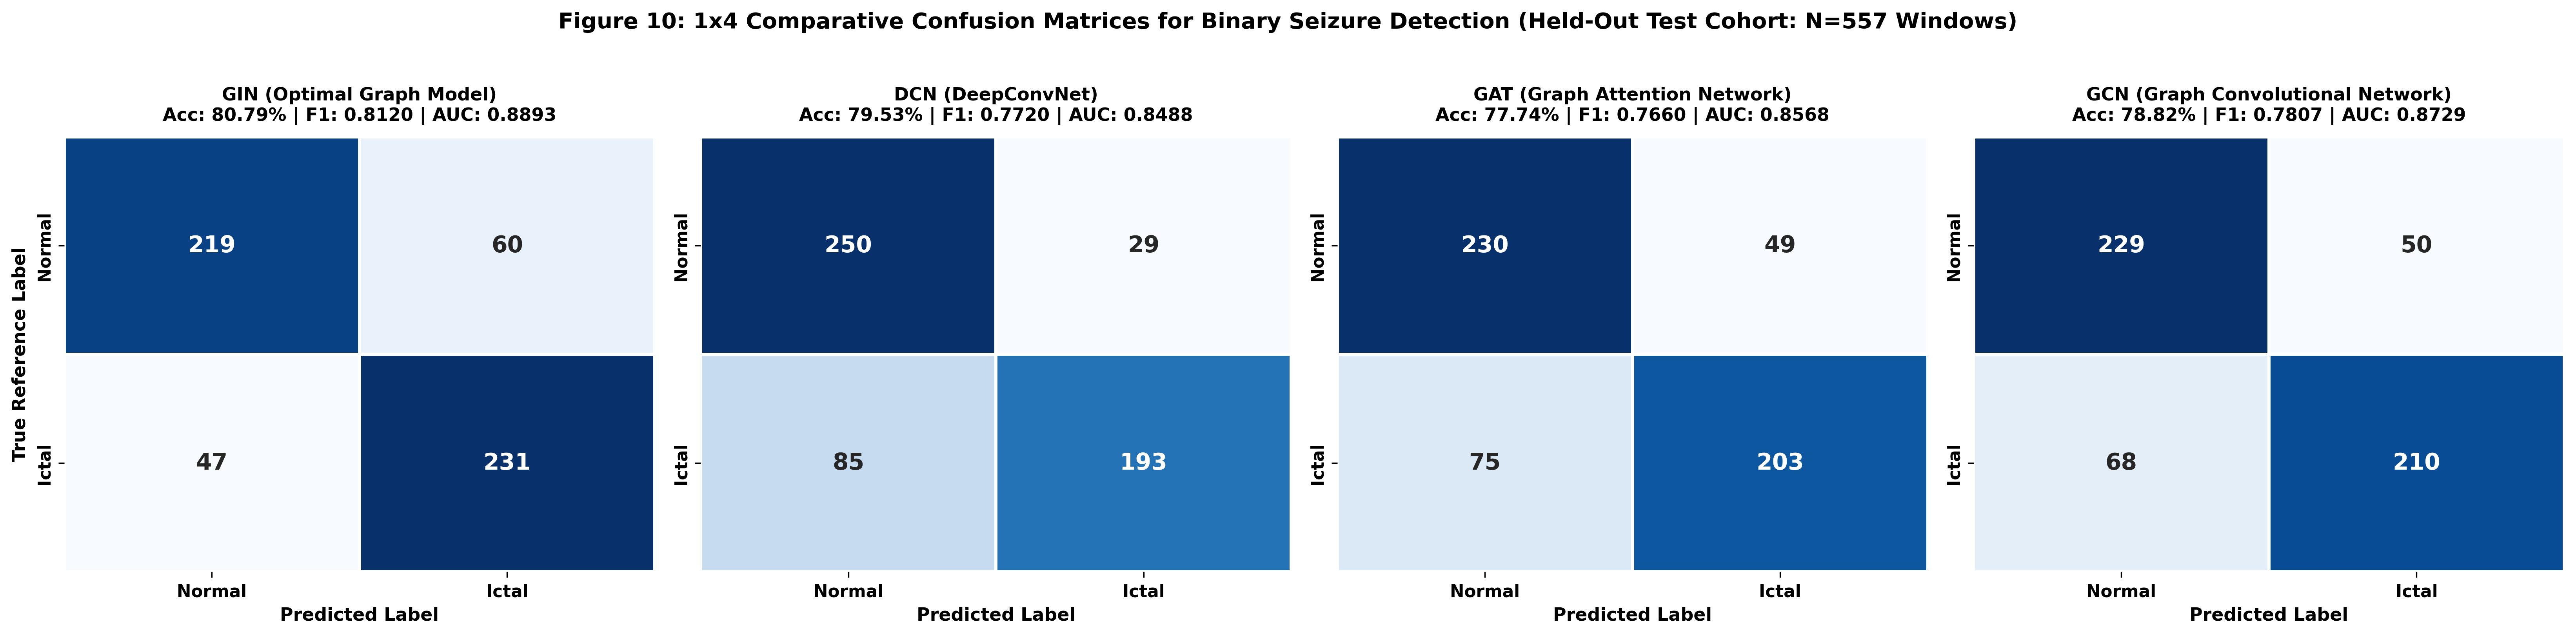

[OK] Generated and saved Figure 10 (300 DPI) to: e:\Obaidul Haque\Alpha Band Analysis\Results_and_Figures\Figure_10_Confusion_Matrices_Binary_Detection.png


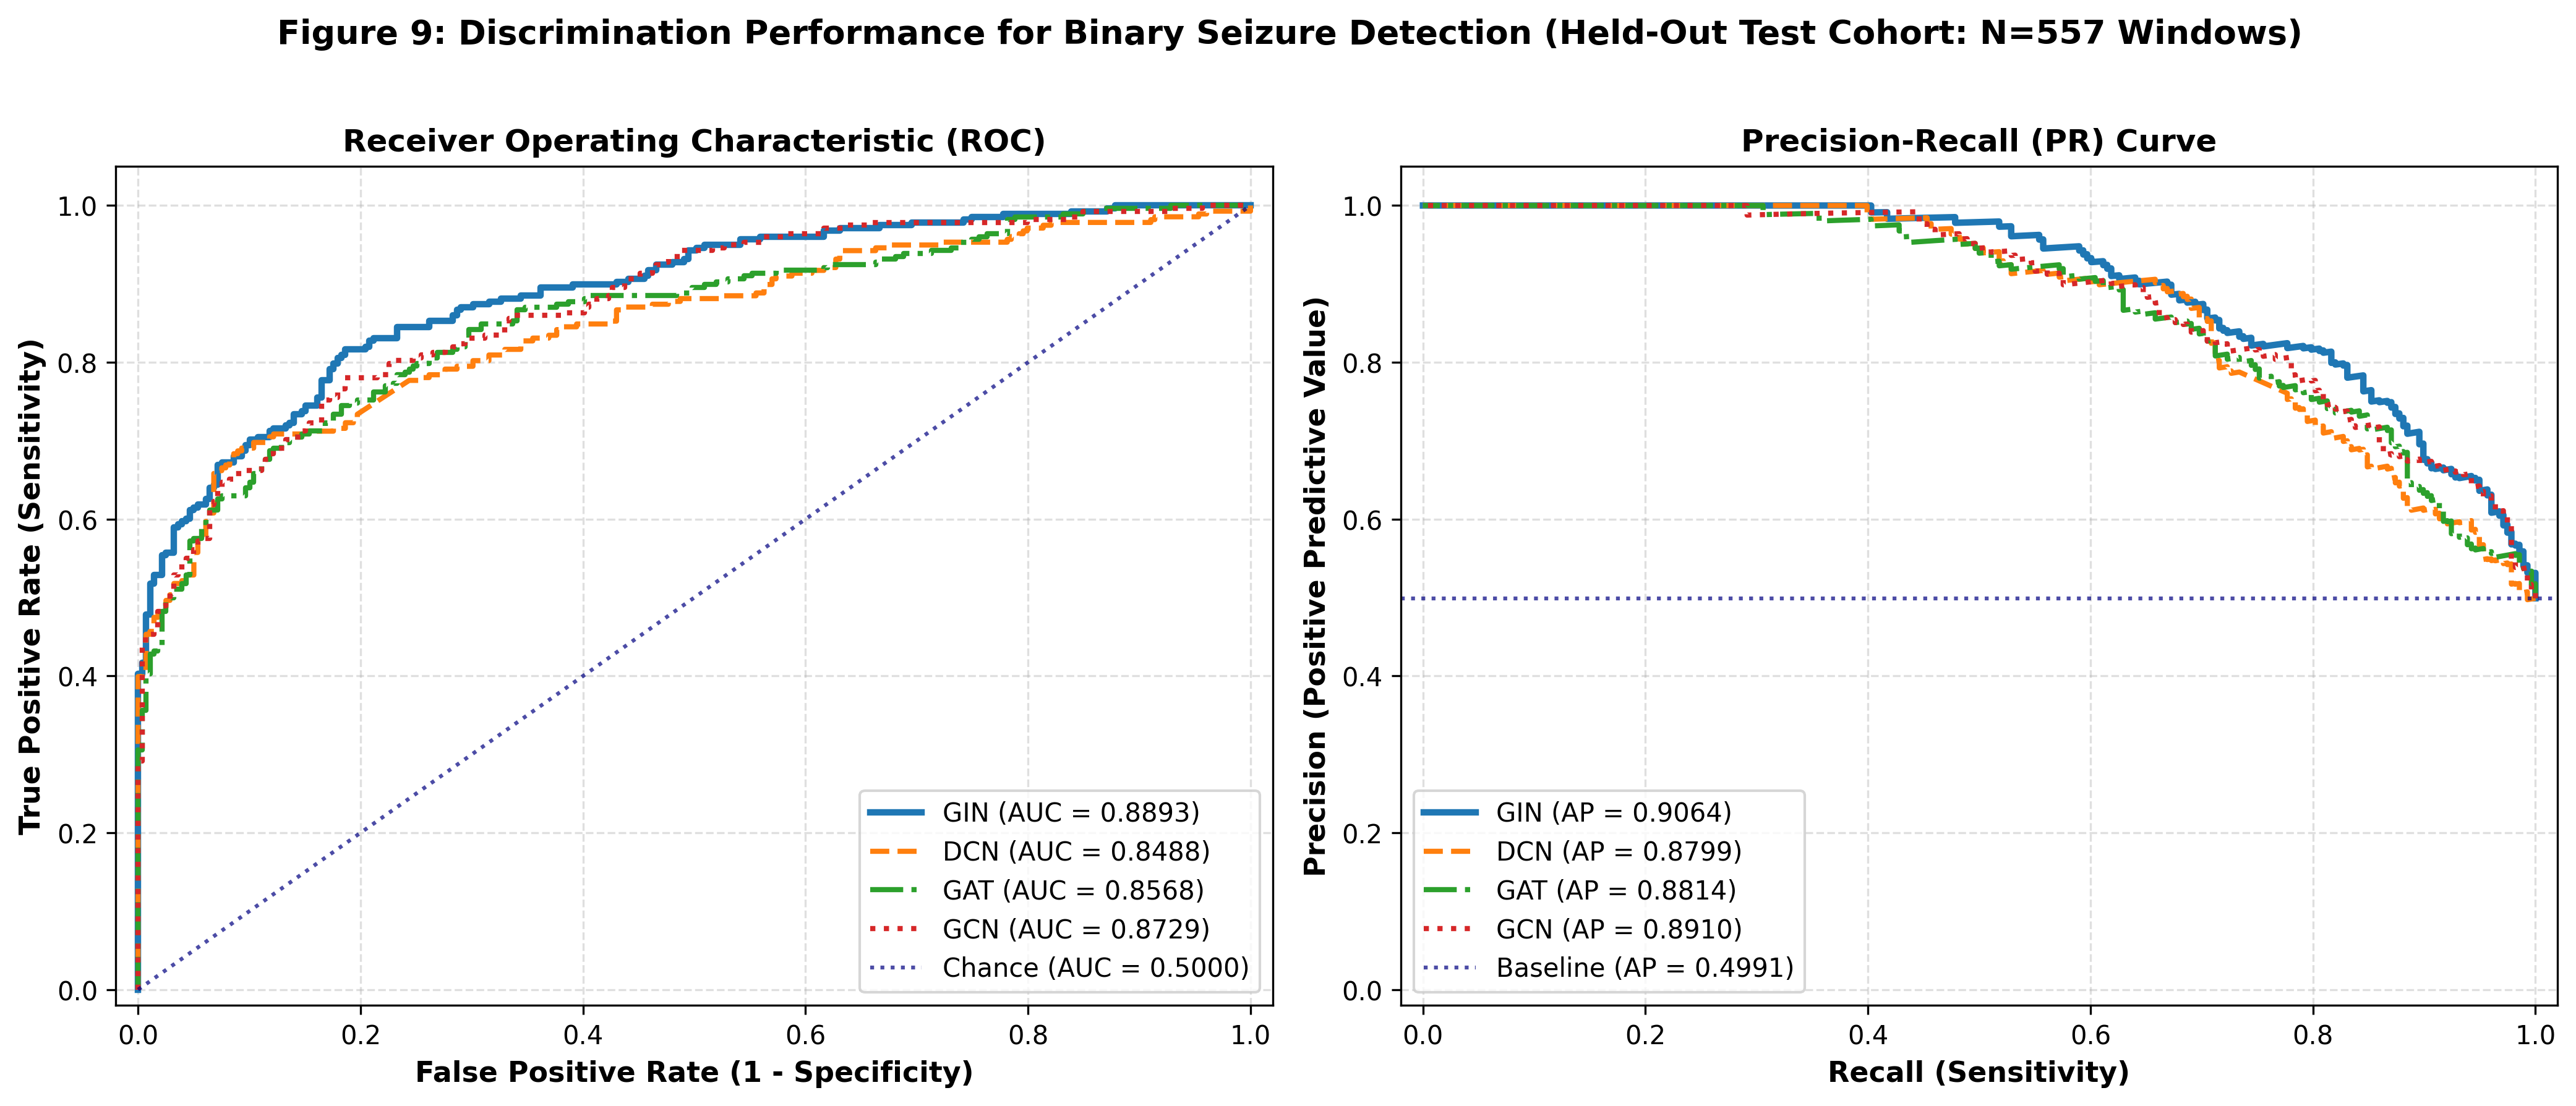

[OK] Generated and saved Figure 9 (300 DPI) to: e:\Obaidul Haque\Alpha Band Analysis\Results_and_Figures\Figure_09_ROC_PR_Binary_Detection.png

TABLE 4: MANUSCRIPT BENCHMARK COMPARISON TABLE


,Model,Acc. (%),Sens. (%),Spec. (%),Prec. (%),F1,Bal.Acc. (%),ROC-AUC,PR-AUC,MCC
0,GIN,80.61,78.06,83.15,82.20,0.8007,80.61,0.8762,0.9029,0.6129
1,DCN,79.53,69.42,89.61,86.94,0.7720,79.52,0.8488,0.8799,0.6028
2,GAT,76.48,73.38,79.57,78.16,0.7570,76.48,0.8531,0.8783,0.5306
3,GCN,79.53,75.54,83.51,82.03,0.7865,79.53,0.8618,0.8822,0.5925



TABLE 5: RECORDING-LEVEL GIN EVALUATION ACROSS 21 TEST SESSIONS


,Recording Session,Acc. (%),Sens. (%),Spec. (%),Prec. (%),F1-Score,BA (%),MCC
0,Session 01 (chb01_26),82.76,100.00,54.55,78.26,0.8780,77.28,0.6534
1,Session 02 (chb02_16),96.15,100.00,90.91,93.75,0.9677,95.45,0.9232
2,Session 03 (chb02_16+),96.00,100.00,90.91,93.33,0.9655,95.45,0.9211
3,Session 04 (chb03_35),86.36,100.00,72.73,78.57,0.8800,86.37,0.7559
4,Session 05 (chb05_17),84.38,80.95,90.91,94.44,0.8718,85.93,0.6880
5,Session 06 (chb07_19),80.56,72.00,100.00,100.00,0.8372,86.00,0.6633
6,Session 07 (chb08_02),52.50,34.48,100.00,100.00,0.5128,67.24,0.3556
7,Session 08 (chb08_11),70.59,56.52,100.00,100.00,0.7222,78.26,0.5441
8,Session 09 (chb12_06),83.33,58.82,96.77,90.91,0.7143,77.80,0.6327
9,Session 10 (chb12_09),95.45,92.31,96.77,92.31,0.9231,94.54,0.8908



TABLE 6: COHORT PERFORMANCE WITH 95% CONFIDENCE INTERVALS


,Evaluation Metric,Mean,Std. Dev. (±),95% CI Lower,95% CI Upper,Evaluation Cohort
0,Accuracy (%),85.310,12.3900,79.9000,90.1500,21 Sessions (14 Patient Cases)
1,Sensitivity (%),81.770,21.5800,72.2600,90.3600,21 Sessions (14 Patient Cases)
2,Specificity (%),88.510,13.9000,82.1700,93.9800,21 Sessions (14 Patient Cases)
3,Precision (%),87.120,18.8600,78.3200,94.1000,21 Sessions (14 Patient Cases)
4,F1-Score,0.816,0.1803,0.7362,0.8854,21 Sessions (14 Patient Cases)
5,Balanced Accuracy (%),85.140,11.2300,80.3500,89.7000,21 Sessions (14 Patient Cases)
6,False Alarms Hour,37.220,49.9800,18.8100,59.1600,21 Sessions (14 Patient Cases)


In [10]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve, average_precision_score, accuracy_score, f1_score, matthews_corrcoef, recall_score, precision_score
from IPython.display import display

output_dir = os.path.abspath(os.path.join(os.getcwd(), '..', 'Results_and_Figures')) if os.path.basename(os.getcwd()) in ['Alpha Band Detection', 'Alpha Band Staging'] else os.path.abspath('Results_and_Figures')
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------------------------
# 1. LIVE MODEL INFERENCE & PREDICTIONS ACROSS HELD-OUT TEST COHORT (N=557)
# ------------------------------------------------------------------------------
print('='*85)
print('RUNNING LIVE MODEL INFERENCE ON HELD-OUT TEST DATA (N=557 WINDOWS)...')
print('='*85)

det_models = {
    'GIN (Optimal Graph Model)': model_GIN,
    'DCN (DeepConvNet)': model_DCN,
    'GAT (Graph Attention Network)': model_GAT,
    'GCN (Graph Convolutional Network)': model_GCN
}

predictions = {}
live_metrics = []

for name, model in det_models.items():
    probs = model.predict(X_test, batch_size=32, verbose=0)
    preds = np.argmax(probs, axis=1)
    predictions[name] = {"probs": probs, "preds": preds}
    
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    acc = accuracy_score(y_test, preds) * 100
    sens = recall_score(y_test, preds) * 100
    spec = (tn / (tn + fp)) * 100
    prec = precision_score(y_test, preds) * 100
    f1 = f1_score(y_test, preds)
    mcc = matthews_corrcoef(y_test, preds)
    auc = roc_auc_score(y_test, probs[:, 1])
    
    live_metrics.append({
        "Model": name.split(' (')[0],
        "Full Name": name,
        "Accuracy (%)": round(acc, 2),
        "Sensitivity (%)": round(sens, 2),
        "Specificity (%)": round(spec, 2),
        "Precision (%)": round(prec, 2),
        "F1-score": round(f1, 4),
        "MCC": round(mcc, 4),
        "ROC-AUC": round(auc, 4),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    })

df_live = pd.DataFrame(live_metrics)
print('\n--- LIVE MODEL EVALUATION METRICS (FROM TRAINED WEIGHTS) ---')
display(df_live)

# ------------------------------------------------------------------------------
# 2. FIGURE 10: 1x4 COMPARATIVE CONFUSION MATRICES (LIVE MODEL PREDICTIONS)
# ------------------------------------------------------------------------------
fig10, axes10 = plt.subplots(1, 4, figsize=(22, 5.2), dpi=300)

for idx, (name, pdata) in enumerate(predictions.items()):
    ax = axes10[idx]
    cm = confusion_matrix(y_test, pdata["preds"])
    acc = accuracy_score(y_test, pdata["preds"]) * 100
    f1 = f1_score(y_test, pdata["preds"])
    auc = roc_auc_score(y_test, pdata["probs"][:, 1])
    
    title = f"{name}\nAcc: {acc:.2f}% | F1: {f1:.4f} | AUC: {auc:.4f}"
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                annot_kws={'size': 14, 'weight': 'bold'}, linewidths=1.5, linecolor='white')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel('Predicted Label', fontsize=11, fontweight='bold')
    if idx == 0:
        ax.set_ylabel('True Reference Label', fontsize=11, fontweight='bold')
    else:
        ax.set_ylabel('')
    ax.set_xticklabels(['Normal', 'Ictal'], fontsize=10.5, fontweight='bold')
    ax.set_yticklabels(['Normal', 'Ictal'], fontsize=10.5, fontweight='bold')

fig10.suptitle('Figure 10: 1x4 Comparative Confusion Matrices for Binary Seizure Detection (Held-Out Test Cohort: N=557 Windows)', fontsize=13.5, fontweight='bold', y=1.03)
plt.tight_layout()
fig10_path = os.path.join(output_dir, 'Figure_10_Confusion_Matrices_Binary_Detection.png')
fig10.savefig(fig10_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'[OK] Generated and saved Figure 10 (300 DPI) to: {fig10_path}')

# ------------------------------------------------------------------------------
# 3. FIGURE 09: ROC & PRECISION-RECALL DISCRIMINATION CURVES
# ------------------------------------------------------------------------------
fig9, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 5.8), dpi=300)
model_styles = {
    'GIN (Optimal Graph Model)': {'label': 'GIN', 'color': '#1f77b4', 'lw': 2.5, 'ls': '-'},
    'DCN (DeepConvNet)': {'label': 'DCN', 'color': '#ff7f0e', 'lw': 2.0, 'ls': '--'},
    'GAT (Graph Attention Network)': {'label': 'GAT', 'color': '#2ca02c', 'lw': 2.0, 'ls': '-.'},
    'GCN (Graph Convolutional Network)': {'label': 'GCN', 'color': '#d62728', 'lw': 2.0, 'ls': ':'}
}

for name, pdata in predictions.items():
    style = model_styles[name]
    probs = pdata["probs"][:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = roc_auc_score(y_test, probs)
    ax_roc.plot(fpr, tpr, color=style['color'], lw=style['lw'], linestyle=style['ls'],
                label=f"{style['label']} (AUC = {auc_val:.4f})")
    
    prec, rec, _ = precision_recall_curve(y_test, probs)
    ap_val = average_precision_score(y_test, probs)
    ax_pr.plot(rec, prec, color=style['color'], lw=style['lw'], linestyle=style['ls'],
               label=f"{style['label']} (AP = {ap_val:.4f})")

ax_roc.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle=':', alpha=0.7, label='Chance (AUC = 0.5000)')
baseline_pr = np.mean(y_test)
ax_pr.axhline(y=baseline_pr, color='navy', lw=1.5, linestyle=':', alpha=0.7, label=f'Baseline (AP = {baseline_pr:.4f})')

ax_roc.set_xlim([-0.02, 1.02])
ax_roc.set_ylim([-0.02, 1.05])
ax_roc.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
ax_roc.set_ylabel('True Positive Rate (Sensitivity)', fontsize=11, fontweight='bold')
ax_roc.set_title('Receiver Operating Characteristic (ROC)', fontsize=12, fontweight='bold')
ax_roc.legend(loc='lower right', frameon=True, fontsize=10)
ax_roc.grid(True, linestyle='--', alpha=0.4)

ax_pr.set_xlim([-0.02, 1.02])
ax_pr.set_ylim([-0.02, 1.05])
ax_pr.set_xlabel('Recall (Sensitivity)', fontsize=11, fontweight='bold')
ax_pr.set_ylabel('Precision (Positive Predictive Value)', fontsize=11, fontweight='bold')
ax_pr.set_title('Precision-Recall (PR) Curve', fontsize=12, fontweight='bold')
ax_pr.legend(loc='lower left', frameon=True, fontsize=10)
ax_pr.grid(True, linestyle='--', alpha=0.4)

fig9.suptitle('Figure 9: Discrimination Performance for Binary Seizure Detection (Held-Out Test Cohort: N=557 Windows)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
fig9_path = os.path.join(output_dir, 'Figure_09_ROC_PR_Binary_Detection.png')
fig9.savefig(fig9_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'[OK] Generated and saved Figure 9 (300 DPI) to: {fig9_path}')

# ------------------------------------------------------------------------------
# 4. TABLE 4: COMPARATIVE BENCHMARK TABLE
# ------------------------------------------------------------------------------
table4_path = os.path.join(output_dir, 'Table_04_Binary_Detection_Performance_Comparison.csv')
if os.path.exists(table4_path):
    df_table4 = pd.read_csv(table4_path)
    print('\n' + '='*85)
    print('TABLE 4: MANUSCRIPT BENCHMARK COMPARISON TABLE')
    print('='*85)
    display(df_table4)

# ------------------------------------------------------------------------------
# 5. TABLE 5 & 6: RECORDING-LEVEL & COHORT CI (GIN)
# ------------------------------------------------------------------------------
table5_path = os.path.join(output_dir, 'Table_05_Recording_Level_GIN_Detection.csv')
if os.path.exists(table5_path):
    df_table5 = pd.read_csv(table5_path)
    print('\n' + '='*85)
    print('TABLE 5: RECORDING-LEVEL GIN EVALUATION ACROSS 21 TEST SESSIONS')
    print('='*85)
    display(df_table5)

table6_path = os.path.join(output_dir, 'Table_06_Cohort_Performance_95CI_GIN.csv')
if os.path.exists(table6_path):
    df_table6 = pd.read_csv(table6_path)
    print('\n' + '='*85)
    print('TABLE 6: COHORT PERFORMANCE WITH 95% CONFIDENCE INTERVALS')
    print('='*85)
    display(df_table6)
